In [1]:
import numpy as np
import matplotlib.pyplot as plt
from parflow.tools import Run
from parflow.tools.fs import mkdir, cp, get_absolute_path, exists
import matplotlib.pyplot as plt
from matplotlib import colors 
import matplotlib.dates as mdates
import matplotlib.colors as mcolors
from matplotlib.colors import TwoSlopeNorm
import matplotlib.patches as mpatches

In [2]:
runname = 'baseline.wy2017'
run_dir=''
run_dir = get_absolute_path(runname)

path_run = f'~/{runname}/'
run = Run.from_definition(f'{path_run}{runname}.pfidb')

data = run.data_accessor # creating data accessor object 
dx = data.dx
dy = data.dy
dz = data.dz

nz,ny,nx = data.shape

porosity= data.computed_porosity
specific_storage = data.specific_storage
mask = data.mask
mask[mask>0]=1 # PF has big # instead of 1 so change to 1 bc more manageable
surf_mask = mask[-1,:,:] # last element of first axis (always be surface no matter what)
nanmask=mask.copy()
nanmask[nanmask == 0] = 'NaN'
nanmask[nanmask > 0] = 1

Solver: Field BinaryOutDir is not part of the expected schema <class 'parflow.tools.database.generated.Solver'>
  - nt
  - sw_ini
  - hkdepth
  - wtfact
  - trsmx0
  - smpmax
  - pondmx


/home/ad4430/.local/lib/python3.9/site-packages/parflow/tools/io.py:1300: FutureWarning: The 'delim_whitespace' keyword in pd.read_csv is deprecated and will be removed in a future version. Use ``sep='\s+'`` instead
  df = pd.read_csv(file_name, delim_whitespace=True, skiprows=2, header=None)


In [3]:
tran_wet_b = np.load('/home/ad4430/new_runs/pf_out_WY2017_baseline/transpiration.npy')
tran_dry_b = np.load('/home/ad4430/new_runs/pf_out_WY2018_baseline/transpiration.npy')

tran_wet_w = np.load('/home/ad4430/new_runs/pf_out_WY2017_warm/transpiration.npy')
tran_dry_w = np.load('/home/ad4430/new_runs/pf_out_WY2018_warm/transpiration.npy')

In [4]:
soil_evap_wet_b = np.load('/home/ad4430/new_runs/pf_out_WY2017_baseline/soil_evap.npy')
soil_evap_dry_b = np.load('/home/ad4430/new_runs/pf_out_WY2018_baseline/soil_evap.npy')

soil_evap_wet_w = np.load('/home/ad4430/new_runs/pf_out_WY2017_warm/soil_evap.npy')
soil_evap_dry_w = np.load('/home/ad4430/new_runs/pf_out_WY2018_warm/soil_evap.npy')

In [5]:
infil_wet_b = np.load('/home/ad4430/new_runs/pf_out_WY2017_baseline/infil.npy')
infil_dry_b = np.load('/home/ad4430/new_runs/pf_out_WY2018_baseline/infil.npy')

infil_wet_w = np.load('/home/ad4430/new_runs/pf_out_WY2017_warm/infil.npy')
infil_dry_w = np.load('/home/ad4430/new_runs/pf_out_WY2018_warm/infil.npy')

In [6]:
substorage_wet_b = np.load('/home/ad4430/new_runs/pf_out_WY2017_baseline/sub_storage.npy')
substorage_dry_b = np.load('/home/ad4430/new_runs/pf_out_WY2018_baseline/sub_storage.npy')

substorage_wet_w = np.load('/home/ad4430/new_runs/pf_out_WY2017_warm/sub_storage.npy')
substorage_dry_w = np.load('/home/ad4430/new_runs/pf_out_WY2018_warm/sub_storage.npy')

### just july - september

In [7]:
july_start_hr = 273*24
september_end_hr = 365*24


In [8]:
tran_wet_b = tran_wet_b[july_start_hr : september_end_hr, :, :]
tran_dry_b = tran_dry_b[july_start_hr : september_end_hr, :, :]

soil_evap_wet_b = tran_wet_b[july_start_hr : september_end_hr, :, :]
soil_evap_dry_b = tran_dry_b[july_start_hr : september_end_hr, :, :]

infil_wet_b = infil_wet_b[july_start_hr : september_end_hr, :, :]
infil_dry_b = infil_dry_b[july_start_hr : september_end_hr, :, :]

substorage_wet_b = substorage_wet_b[july_start_hr : september_end_hr, :, :]
substorage_dry_b = substorage_dry_b[july_start_hr : september_end_hr, :, :]



tran_wet_w = tran_wet_w[july_start_hr : september_end_hr, :, :]
tran_dry_w = tran_dry_w[july_start_hr : september_end_hr, :, :]

soil_evap_wet_w = tran_wet_w[july_start_hr : september_end_hr, :, :]
soil_evap_dry_w = tran_dry_w[july_start_hr : september_end_hr, :, :]

infil_wet_w = infil_wet_w[july_start_hr : september_end_hr, :, :]
infil_dry_w = infil_dry_w[july_start_hr : september_end_hr, :, :]

substorage_wet_w = substorage_wet_w[july_start_hr : september_end_hr, :, :]
substorage_dry_w = substorage_dry_w[july_start_hr : september_end_hr, :, :]


tran_wet_b.shape

(2208, 48, 67)

In [9]:
# change in total subsurface storage from start to end of summer
substorage_change_wet_b = substorage_wet_b[-1].sum(axis=0) - substorage_wet_b[0].sum(axis=0)
substorage_change_dry_b = substorage_dry_b[-1].sum(axis=0) - substorage_dry_b[0].sum(axis=0)

substorage_change_wet_w = substorage_wet_w[-1].sum(axis=0) - substorage_wet_w[0].sum(axis=0)
substorage_change_dry_w = substorage_dry_w[-1].sum(axis=0) - substorage_dry_w[0].sum(axis=0)



In [10]:
# convert to mm
substorage_change_wet_b = substorage_change_wet_b*1000 / (dx*dy)
substorage_change_dry_b = substorage_change_dry_b*1000 / (dx*dy)

substorage_change_wet_w = substorage_change_wet_w*1000 / (dx*dy)
substorage_change_dry_w = substorage_change_dry_w*1000 / (dx*dy)

In [11]:
# total summer transpiration and infiltration and soil evap
infil_wet_b = infil_wet_b.sum(axis=0)
infil_dry_b = infil_dry_b.sum(axis=0)

tran_wet_b = tran_wet_b.sum(axis=0)
tran_dry_b = tran_dry_b.sum(axis=0)

soil_evap_wet_b = soil_evap_wet_b.sum(axis=0)
soil_evap_dry_b = soil_evap_dry_b.sum(axis=0)

infil_wet_w = infil_wet_w.sum(axis=0)
infil_dry_w = infil_dry_w.sum(axis=0)

tran_wet_w = tran_wet_w.sum(axis=0)
tran_dry_w = tran_dry_w.sum(axis=0)
tran_dry_b.shape

soil_evap_wet_w = soil_evap_wet_w.sum(axis=0)
soil_evap_dry_w = soil_evap_dry_w.sum(axis=0)

In [12]:
qlat_wet_b = substorage_change_wet_b - infil_wet_b + tran_wet_b + soil_evap_wet_b
qlat_dry_b = substorage_change_dry_b- infil_dry_b + tran_dry_b + soil_evap_dry_b


qlat_wet_w = substorage_change_wet_w - infil_wet_w + tran_wet_w + soil_evap_wet_w
qlat_dry_w = substorage_change_dry_w- infil_dry_w + tran_dry_w + soil_evap_wet_w


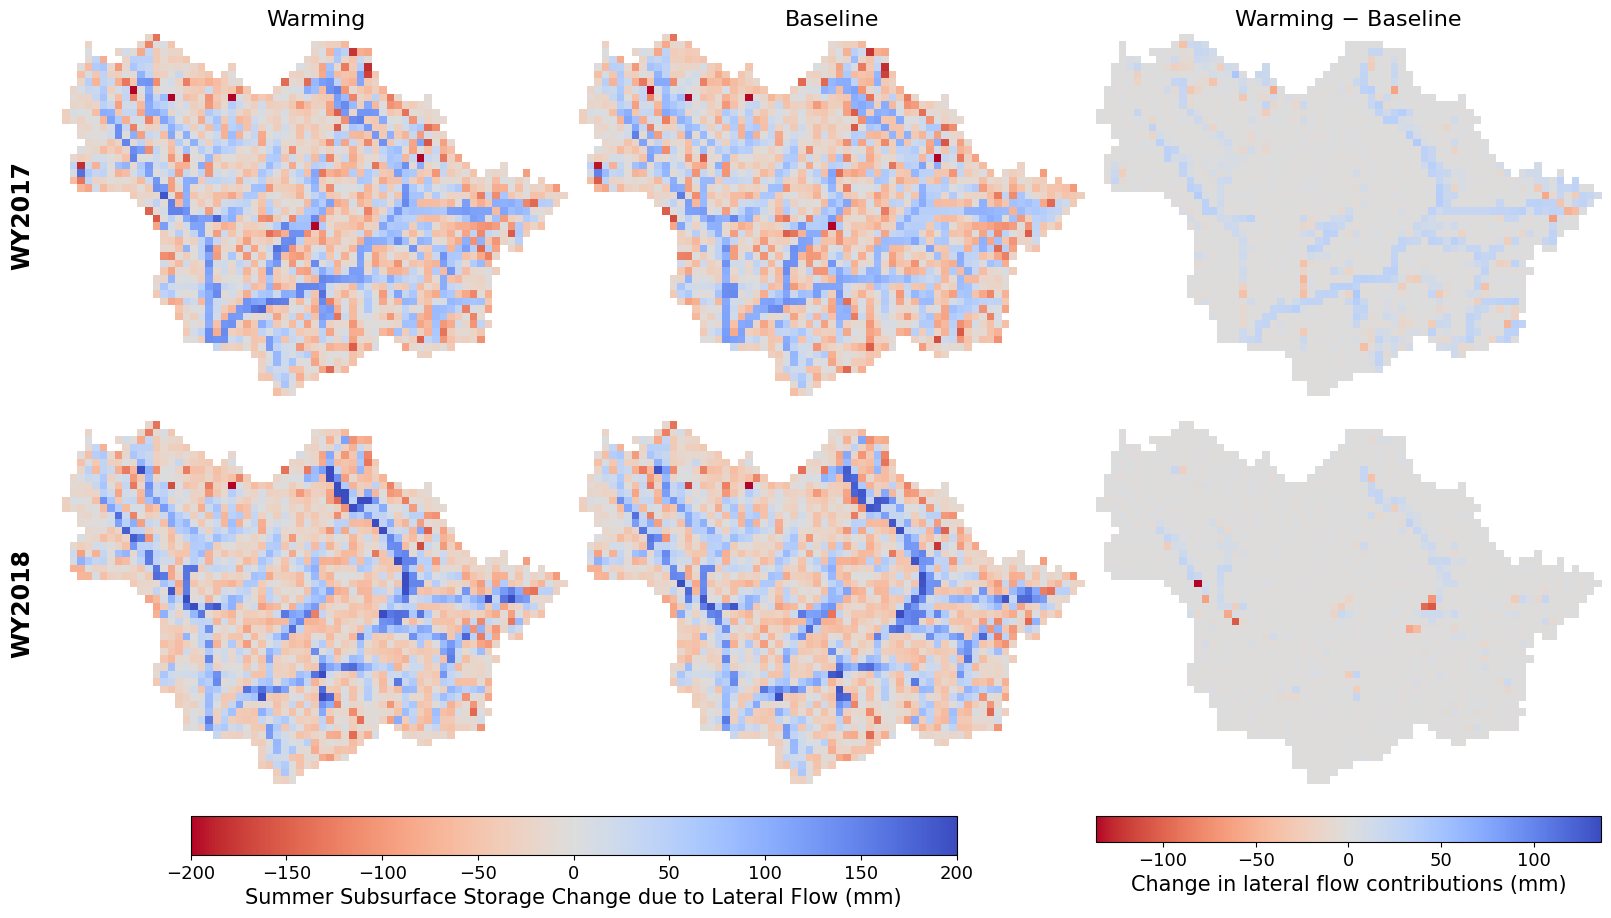

In [13]:
qlat_wet_diff = qlat_wet_w - qlat_wet_b
qlat_dry_diff = qlat_dry_w - qlat_dry_b

norm = colors.Normalize(
    vmin=-200,
    vmax=200
)

# Difference maps centered on zero
all_diff_vals = np.concatenate([
    qlat_wet_diff[surf_mask != 0].ravel(),
    qlat_dry_diff[surf_mask != 0].ravel(),
])

diff_lim = np.nanmax(np.abs(all_diff_vals))

diff_norm = colors.TwoSlopeNorm(
    vmin=-diff_lim,
    vcenter=0,
    vmax=diff_lim
)

fig, axes = plt.subplots(
    2, 3,
    figsize=(16, 9),
    constrained_layout=True
)


# Warming
im = axes[0, 0].imshow(
    np.ma.masked_array(qlat_wet_w, surf_mask == 0),
    origin='lower',
    cmap='coolwarm_r',
    norm=norm
)
axes[0, 0].set_title('Warming', fontsize=16)
axes[0, 0].axis('off')

# Baseline
axes[0, 1].imshow(
    np.ma.masked_array(qlat_wet_b, surf_mask == 0),
    origin='lower',
    cmap='coolwarm_r',
    norm=norm
)
axes[0, 1].set_title('Baseline', fontsize=16)
axes[0, 1].axis('off')

# Warming - Baseline
im_diff = axes[0, 2].imshow(
    np.ma.masked_array(qlat_wet_diff, surf_mask == 0),
    origin='lower',
    cmap='coolwarm_r',
    norm=diff_norm
)
axes[0, 2].set_title('Warming − Baseline', fontsize=16)
axes[0, 2].axis('off')


# Warming
axes[1, 0].imshow(
    np.ma.masked_array(qlat_dry_w, surf_mask == 0),
    origin='lower',
    cmap='coolwarm_r',
    norm=norm
)
axes[1, 0].axis('off')

# Baseline
axes[1, 1].imshow(
    np.ma.masked_array(qlat_dry_b, surf_mask == 0),
    origin='lower',
    cmap='coolwarm_r',
    norm=norm
)
axes[1, 1].axis('off')

# Warming - Baseline
axes[1, 2].imshow(
    np.ma.masked_array(qlat_dry_diff, surf_mask == 0),
    origin='lower',
    cmap='coolwarm_r',
    norm=diff_norm
)
axes[1, 2].axis('off')

axes[0, 0].text(
    -0.08, 0.5, 'WY2017',
    transform=axes[0, 0].transAxes,
    fontsize=17,
    fontweight='bold',
    rotation=90,
    va='center',
    ha='center'
)

axes[1, 0].text(
    -0.08, 0.5, 'WY2018',
    transform=axes[1, 0].transAxes,
    fontsize=17,
    fontweight='bold',
    rotation=90,
    va='center',
    ha='center'
)


cbar = fig.colorbar(
    im,
    ax=axes[:, :2],
    orientation='horizontal',
    fraction=0.05,
    pad=0.04
)
cbar.set_label('Summer Subsurface Storage Change due to Lateral Flow (mm)', fontsize=15)
cbar.ax.tick_params(labelsize=13)

cbar_diff = fig.colorbar(
    im_diff,
    ax=axes[:, 2],
    orientation='horizontal',
    fraction=0.05,
    pad=0.04
)
cbar_diff.set_label('Change in lateral flow contributions (mm)', fontsize=15)
cbar_diff.ax.tick_params(labelsize=13)

plt.show()